# Task 5: Experiments (ablation and preprocessing order)
Uses the modeling table and the **final model** chosen in the model comparison (`results/final_model.json`).
Existing files are only read; outputs go to `results_exp/` and `figures_exp/`.

| Part | Content |
|---|---|
| 1 | Load data, final model and settings; reproduce the saved validation score |
| 2 | Feature-group ablation: remove one group at a time, and each group alone |
| 3 | Paired race-bootstrap intervals for the ablation changes |
| 4 | Preprocessing experiment P1: fit on train only vs fit on all rows (leaky) |
| 5 | Preprocessing experiment P2: impute then scale vs scale then impute |
| 6 | Conclusions |

## 1. Setup and baseline reproduction

In [1]:
import os, glob, json, copy, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, precision_recall_curve
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 180)

def find_clean_dir():
    if os.path.exists("/kaggle/working/clean/modeling_table.parquet"):
        return "/kaggle/working/clean"
    here = os.path.abspath(os.getcwd())
    for _ in range(4):
        hits = sorted(glob.glob(os.path.join(here, "**", "clean", "modeling_table.parquet"), recursive=True))
        if hits:
            return os.path.dirname(hits[0])
        here = os.path.dirname(here)
    raise FileNotFoundError("clean/modeling_table.parquet not found: run feature engineering first.")

CLEAN = find_clean_dir()
ROOT = os.path.dirname(os.path.abspath(CLEAN))
RESULTS = os.path.join(ROOT, "results")
OUT_RES, OUT_FIG = os.path.join(ROOT, "results_exp"), os.path.join(ROOT, "figures_exp")
os.makedirs(OUT_RES, exist_ok=True); os.makedirs(OUT_FIG, exist_ok=True)

cfg = json.load(open(os.path.join(CLEAN, "feature_config.json")))
mdl = pd.read_parquet(os.path.join(CLEAN, "modeling_table.parquet")).sort_values(["race_order", "driverId"]).reset_index(drop=True)
TARGET, FEATURES = cfg["target"], list(cfg["features"])
BINARY, CONTINUOUS = list(cfg["binary"]), list(cfg["continuous"])
GROUPS = {g: [f for f in fs if f in FEATURES] for g, fs in cfg["groups"].items()}
SEED = int(cfg.get("seed", 42))
train, val, test = (mdl[mdl["split"] == s].copy() for s in ("train", "val", "test"))
assert train["race_order"].max() < val["race_order"].min() and val["race_order"].max() < test["race_order"].min()

final = json.load(open(os.path.join(RESULTS, "final_model.json")))
FINAL = final["final_model"]
saved = json.load(open(os.path.join(RESULTS, f"{FINAL}.json")))
print(f"final model: {final['label']} ({FINAL}) | settings: {saved['params']}")
print(f"{len(FEATURES)} features in {len(GROUPS)} groups:", {g: len(f) for g, f in GROUPS.items()})
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")

final model: Logistic regression (logreg) | settings: {'C': 0.01}
29 features in 7 groups: {'grid': 6, 'qualifying': 4, 'driver_form': 4, 'constructor_form': 2, 'standings': 6, 'circuit_history': 3, 'context': 4}
train 22,441 | val 774 | test 1,351


**Same preprocessing, metrics and threshold rule as the modeling notebooks:** median imputation with missing indicators then scaling (linear models and the network), imputation only (random forest), no change (XGBoost); threshold = best F1 on validation, reused on test. Every run refits the preprocessor on the training rows of the features it uses.

In [2]:
def make_preprocessor(cont, binary, kind="linear", order="impute_then_scale"):
    imp = lambda: SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
    if kind == "native":
        return ColumnTransformer([("all", "passthrough", cont + binary)])
    if kind == "tree":
        steps = [("imp", imp())]
    elif order == "impute_then_scale":
        steps = [("imp", imp()), ("sc", StandardScaler())]
    elif order == "scale_then_impute":
        steps = [("sc", StandardScaler()), ("imp", imp())]
    else:
        raise ValueError(order)
    parts = [("cont", Pipeline(steps), cont)] if cont else []
    if binary:
        parts.append(("bin", SimpleImputer(strategy="most_frequent", keep_empty_features=True), binary))
    return ColumnTransformer(parts)

class WeightedMLP(BaseEstimator, ClassifierMixin):
    """The shallow network as trained in nn_models: podium rows repeated ~6.4x per epoch, fixed number of epochs."""
    def __init__(self, hidden=(64, 32), alpha=1e-2, lr=1e-3, epochs=8, batch=256, seed=42):
        self.hidden, self.alpha, self.lr, self.epochs, self.batch, self.seed = hidden, alpha, lr, epochs, batch, seed
    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y); rng = np.random.default_rng(self.seed)
        w = (y == 0).sum() / (y == 1).sum(); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
        self.net_ = MLPClassifier(hidden_layer_sizes=tuple(self.hidden), alpha=self.alpha, learning_rate_init=self.lr,
                                  batch_size=self.batch, random_state=self.seed)
        for _ in range(int(self.epochs)):
            idx = np.concatenate([neg, np.repeat(pos, int(w)), pos[rng.random(len(pos)) < w - int(w)]]); rng.shuffle(idx)
            self.net_.partial_fit(X[idx], y[idx], classes=[0, 1])
        self.classes_ = self.net_.classes_; return self
    def predict_proba(self, X): return self.net_.predict_proba(np.asarray(X, float))

def make_model(name, seed=SEED):
    p = saved["params"] if name == FINAL else {}
    if name in ("logreg", "lr"):
        return LogisticRegression(class_weight="balanced", max_iter=5000, C=p.get("C", 0.01)), "linear"
    if name == "rf":
        keep = {k: v for k, v in p.items() if k in ("n_estimators", "max_depth", "min_samples_leaf", "max_features")}
        return RandomForestClassifier(class_weight="balanced_subsample", random_state=seed, n_jobs=4, **{"n_estimators": 300, **keep}), "tree"
    if name == "xgb":
        from xgboost import XGBClassifier
        keep = {k: v for k, v in p.items() if k in ("n_estimators", "max_depth", "learning_rate", "min_child_weight", "subsample", "colsample_bytree")}
        w = float((train[TARGET] == 0).sum() / (train[TARGET] == 1).sum())
        return XGBClassifier(tree_method="hist", scale_pos_weight=w, random_state=seed, n_jobs=4, verbosity=0, **keep), "native"
    if name == "nn":
        return WeightedMLP(hidden=tuple(p.get("hidden", (64, 32))), alpha=p.get("alpha", 1e-2), lr=p.get("lr", 1e-3),
                           epochs=p.get("epochs", 8), seed=seed), "linear"
    raise ValueError(name)

STOCHASTIC = {"rf", "xgb", "nn"}
SEEDS = [SEED + i for i in range(5)] if FINAL in STOCHASTIC else [SEED]     # deterministic models need one run

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[int(np.nanargmax(f1[:-1]))])

def metrics_at(d, p, thr):
    y, p = d[TARGET].to_numpy(), np.asarray(p, float); yhat = (p >= thr).astype(int)
    top3 = d.assign(_p=p).sort_values(["raceId", "_p"], ascending=[True, False]).groupby("raceId").head(3)
    return dict(roc_auc=float(roc_auc_score(y, p)), pr_auc=float(average_precision_score(y, p)), f1=float(f1_score(y, yhat, zero_division=0)),
                precision=float(precision_score(y, yhat, zero_division=0)), recall=float(recall_score(y, yhat, zero_division=0)),
                top3_precision=float(top3[TARGET].mean()), threshold=float(thr))

def fit_eval(feats, name=FINAL, seed=SEED, order="impute_then_scale", fit_pre_on=None):
    """Fit preprocessing (on train, or on `fit_pre_on` for the leaky experiment) + model on train; threshold from validation."""
    cont, binary = [f for f in feats if f in CONTINUOUS], [f for f in feats if f in BINARY]
    model, kind = make_model(name, seed)
    pre = make_preprocessor(cont, binary, kind, order).fit((train if fit_pre_on is None else fit_pre_on)[feats])
    model.fit(pre.transform(train[feats]), train[TARGET])
    p = {s: model.predict_proba(pre.transform(d[feats]))[:, 1] for s, d in (("train", train), ("val", val), ("test", test))}
    thr = best_f1_threshold(val[TARGET], p["val"])
    return dict(metrics={s: metrics_at(d, p[s], thr) for s, d in (("train", train), ("val", val), ("test", test))}, p=p, thr=thr)

base = fit_eval(FEATURES)
check = pd.DataFrame({"reproduced": base["metrics"]["val"], "saved": saved["val"]}).dropna()
check["abs_diff"] = (check["reproduced"] - check["saved"]).abs()
display(check.round(4))
print("Reproduction OK" if check.loc["pr_auc", "abs_diff"] < 0.01 else
      "Note: reproduced validation PR-AUC differs from the saved run (stochastic model); ablation compares runs made here, so it stays consistent.")

,reproduced,saved,abs_diff
roc_auc,0.9329,0.9329,0.0
pr_auc,0.7369,0.7369,0.0
f1,0.7109,0.7109,0.0
precision,0.6547,0.6547,0.0
recall,0.7778,0.7778,0.0
top3_precision,0.6838,0.6838,0.0
threshold,0.6710,0.6710,0.0


Reproduction OK


## 2. Feature-group ablation
Two views, both scored on **validation** (test also reported):
- **Leave one group out:** all features except one group. The change vs the full model shows how much the model *relies* on that group, given the others.
- **Only this group:** one group alone. Shows how much signal the group carries *on its own*.

Grid and qualifying carry overlapping information (both reflect starting pace), so removing one can look small because the other stands in for it; the "only this group" view shows that.

In [3]:
runs = [("full", "full", FEATURES)]
for g, fs in GROUPS.items():
    runs += [("leave_one_group_out", g, [f for f in FEATURES if f not in fs]), ("only_this_group", g, fs)]

rows, preds = [], {}
for run_type, g, feats in runs:
    for s in SEEDS:
        r = fit_eval(feats, seed=s)
        preds[(run_type, g, s)] = r["p"]["val"]
        for split, m in r["metrics"].items():
            rows.append(dict(run_type=run_type, group=g, n_features=len(feats), seed=s, split=split, **m))
abl = pd.DataFrame(rows)
abl.to_csv(os.path.join(OUT_RES, "ablation_all_runs.csv"), index=False)

summ = abl.groupby(["run_type", "group", "n_features", "split"])[["pr_auc", "roc_auc", "f1", "top3_precision"]].mean().reset_index()
full_val = summ[(summ.run_type == "full") & (summ.split == "val")].iloc[0]
view = summ[summ.split.isin(["val", "test"])].pivot_table(index=["run_type", "group", "n_features"], columns="split", values=["pr_auc", "roc_auc", "f1"])
display(view.round(4))

f1          pr_auc         roc_auc        
split                                              test     val    test     val    test     val
run_type            group            n_features                                                
full                full             29          0.6654  0.7109  0.7218  0.7369  0.9361  0.9329
leave_one_group_out circuit_history  26          0.6617  0.7109  0.7225  0.7342  0.9362  0.9331
                    constructor_form 27          0.6778  0.7094  0.7171  0.7402  0.9348  0.9334
                    context          25          0.6641  0.7063  0.7216  0.7363  0.9365  0.9324
                    driver_form      25          0.6855  0.7115  0.7210  0.7267  0.9367  0.9312
                    grid             23          0.5455  0.6964  0.6913  0.7270  0.9258  0.9279
                    qualifying       25          0.6747  0.7063  0.7199  0.7201  0.9382  0.9273
                    standings        23          0.6516  0.7082  0.7200  0.7313  0.9362  0.9321
only_this_group     circuit_history  3           0.3516  0.4076  0.2691  0.3246  0.6742  0.7142
                    constructor_form 2           0.5352  0.6452  0.5145  0.5814  0.8843  0.8923
                    context          4           0.1803  0.3427  0.1438  0.1901  0.4868  0.5972
                    driver_form      4           0.5322  0.7029  0.5468  0.6328  0.8823  0.8867
                    grid             6           0.6634  0.7043  0.6812  0.6664  0.9266  0.9170
                    qualifying       4           0.6427  0.7009  0.6482  0.6675  0.9098  0.9232
                    standings        6           0.5367  0.6582  0.5675  0.6557  0.8848  0.8837

## 3. How big is each change? Paired race-bootstrap interval
The same resampled races are used for the full model and the ablated model, so the interval is for the **difference**. An interval that excludes 0 means the change is larger than validation noise.

Full model validation PR-AUC: 0.7369 (no-skill = 0.151)


,group,n_features,delta_pr_auc,ci_low,ci_high,clearly_needed,pr_auc_group_alone
0,qualifying,4,-0.0168,-0.0329,-0.0013,True,0.6675
1,driver_form,4,-0.0103,-0.0265,0.0091,False,0.6328
2,grid,6,-0.0100,-0.0262,0.0042,False,0.6664
3,standings,6,-0.0057,-0.0209,0.0096,False,0.6557
4,circuit_history,3,-0.0027,-0.0096,0.0020,False,0.3246
5,context,4,-0.0007,-0.0072,0.0085,False,0.1901
6,constructor_form,2,0.0032,-0.0058,0.0116,False,0.5814


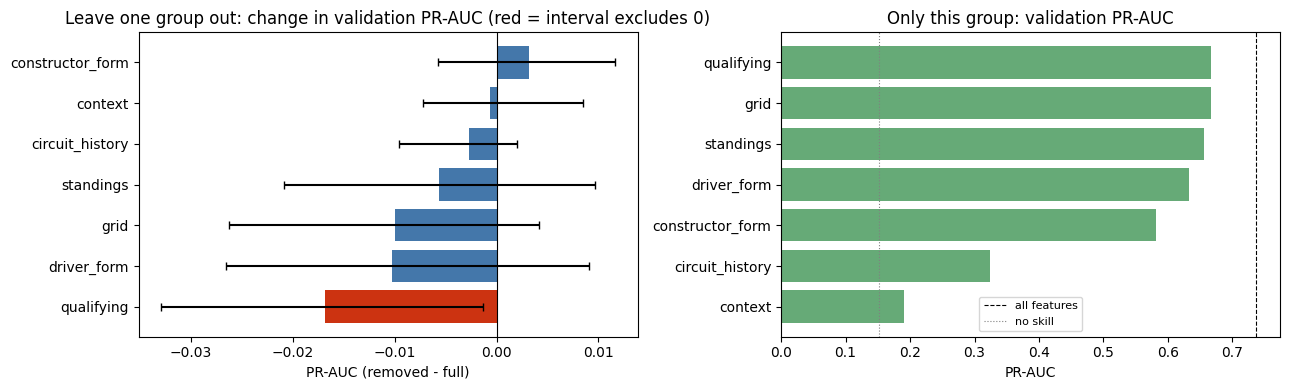

In [4]:
def paired_delta_ci(p_full, p_alt, d=val, metric=average_precision_score, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed); y = d[TARGET].to_numpy()
    races = d["raceId"].to_numpy(); idx_by_race = [np.where(races == r)[0] for r in np.unique(races)]
    deltas = []
    for _ in range(n_boot):
        idx = np.concatenate([idx_by_race[i] for i in rng.integers(0, len(idx_by_race), len(idx_by_race))])
        if y[idx].min() == y[idx].max(): continue
        deltas.append(metric(y[idx], p_alt[idx]) - metric(y[idx], p_full[idx]))
    return np.percentile(deltas, [2.5, 97.5])

ci_rows = []
for g in GROUPS:
    d_pr = [average_precision_score(val[TARGET], preds[("leave_one_group_out", g, s)]) - average_precision_score(val[TARGET], preds[("full", "full", s)]) for s in SEEDS]
    lo, hi = paired_delta_ci(preds[("full", "full", SEEDS[0])], preds[("leave_one_group_out", g, SEEDS[0])])
    only = summ[(summ.run_type == "only_this_group") & (summ.group == g) & (summ.split == "val")]["pr_auc"].iloc[0]
    ci_rows.append(dict(group=g, n_features=len(GROUPS[g]), delta_pr_auc=np.mean(d_pr), ci_low=lo, ci_high=hi,
                        clearly_needed=bool(hi < 0), pr_auc_group_alone=only))
ci = pd.DataFrame(ci_rows).sort_values("delta_pr_auc").reset_index(drop=True)
ci.to_csv(os.path.join(OUT_RES, "ablation_delta_ci.csv"), index=False)
print(f"Full model validation PR-AUC: {full_val['pr_auc']:.4f} (no-skill = {val[TARGET].mean():.3f})")
display(ci.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
y = np.arange(len(ci))
axes[0].barh(y, ci["delta_pr_auc"], color=np.where(ci["clearly_needed"], "#CC3311", "#4477AA"))
axes[0].errorbar(ci["delta_pr_auc"], y, xerr=[ci["delta_pr_auc"] - ci["ci_low"], ci["ci_high"] - ci["delta_pr_auc"]], fmt="none", ecolor="k", capsize=3)
axes[0].axvline(0, color="k", lw=0.8); axes[0].set_yticks(y); axes[0].set_yticklabels(ci["group"])
axes[0].set(title="Leave one group out: change in validation PR-AUC (red = interval excludes 0)", xlabel="PR-AUC (removed - full)")
alone = ci.sort_values("pr_auc_group_alone")
axes[1].barh(alone["group"], alone["pr_auc_group_alone"], color="#66AA77")
axes[1].axvline(full_val["pr_auc"], color="k", ls="--", lw=0.8, label="all features")
axes[1].axvline(val[TARGET].mean(), color="grey", ls=":", lw=0.8, label="no skill")
axes[1].set(title="Only this group: validation PR-AUC", xlabel="PR-AUC"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_FIG, "ablation.png"), dpi=150); plt.show()

## 4. Preprocessing experiment P1: when are the preprocessing statistics learned?
- **Correct:** split first, then fit the imputer and scaler on training rows only.
- **Leaky:** fit them on all rows (train + validation + test) before splitting, so medians and standard deviations have seen the evaluation seasons.

Same model and features; only the rows used to fit preprocessing change.

In [5]:
p1_rows = []
for label, fit_rows in [("correct: fit on train only", None), ("leaky: fit on all rows", mdl)]:
    r = fit_eval(FEATURES, fit_pre_on=fit_rows)
    for split in ("val", "test"):
        p1_rows.append(dict(pipeline=label, split=split, **r["metrics"][split]))
p1 = pd.DataFrame(p1_rows); p1.to_csv(os.path.join(OUT_RES, "p1_fit_scope.csv"), index=False)
display(p1.pivot(index="pipeline", columns="split", values=["pr_auc", "roc_auc", "f1", "threshold"]).round(4))

cont = make_preprocessor(CONTINUOUS, [], "linear").fit(train[FEATURES])
leak = make_preprocessor(CONTINUOUS, [], "linear").fit(mdl[FEATURES])
imp_c, imp_l = cont.named_transformers_["cont"]["imp"], leak.named_transformers_["cont"]["imp"]
sc_c, sc_l = cont.named_transformers_["cont"]["sc"], leak.named_transformers_["cont"]["sc"]
shift = pd.DataFrame({"median_train": imp_c.statistics_, "median_all_rows": imp_l.statistics_,
                      "std_train": sc_c.scale_[:len(CONTINUOUS)], "std_all_rows": sc_l.scale_[:len(CONTINUOUS)]}, index=CONTINUOUS)
shift["median_shift_in_std"] = (shift["median_all_rows"] - shift["median_train"]).abs() / shift["std_train"]
print("Largest changes in the learned statistics when evaluation rows leak into fitting:")
display(shift.sort_values("median_shift_in_std", ascending=False).head(5).round(3))

pr_auc         roc_auc              f1         threshold        
split                         test     val    test     val    test     val      test     val
pipeline                                                                                    
correct: fit on train only  0.7218  0.7369  0.9361  0.9329  0.6654  0.7109    0.6710  0.6710
leaky: fit on all rows      0.7218  0.7372  0.9361  0.9330  0.6654  0.7109    0.6702  0.6702

Largest changes in the learned statistics when evaluation rows leak into fitting:


,median_train,median_all_rows,std_train,std_all_rows,median_shift_in_std
drv_circuit_prev_starts,1.000,2.000,3.030,3.211,0.330
quali_gap_pct,1.826,1.657,1.120,1.148,0.151
q1_gap_pct,1.495,1.340,1.153,1.167,0.135
drv_career_starts,41.000,45.000,61.575,68.780,0.065
circuit_front_row_podium_rate,0.562,0.571,0.142,0.147,0.063


## 5. Preprocessing experiment P2: impute then scale vs scale then impute
- **Impute then scale (used):** missing values get the median, then everything is standardised.
- **Scale then impute:** standardise first (missing values ignored), then fill gaps with the median of the *scaled* column.

The difference shows on features with many gaps (qualifying is missing for about 60% of training rows).

pr_auc         roc_auc              f1        
split                test     val    test     val    test     val
order                                                            
impute_then_scale  0.7218  0.7369  0.9361  0.9329  0.6654  0.7109
scale_then_impute  0.7223  0.7335  0.9372  0.9317  0.6705  0.7115

,order,feature,missing_share,mean,std,min,max
0,impute_then_scale,quali_pos,0.631,-0.000,1.000,-2.618,3.845
1,impute_then_scale,quali_gap_pct,0.637,0.000,1.000,-1.751,14.930
2,scale_then_impute,quali_pos,0.631,-0.034,0.608,-1.627,2.305
3,scale_then_impute,quali_gap_pct,0.637,-0.129,0.610,-1.198,8.985


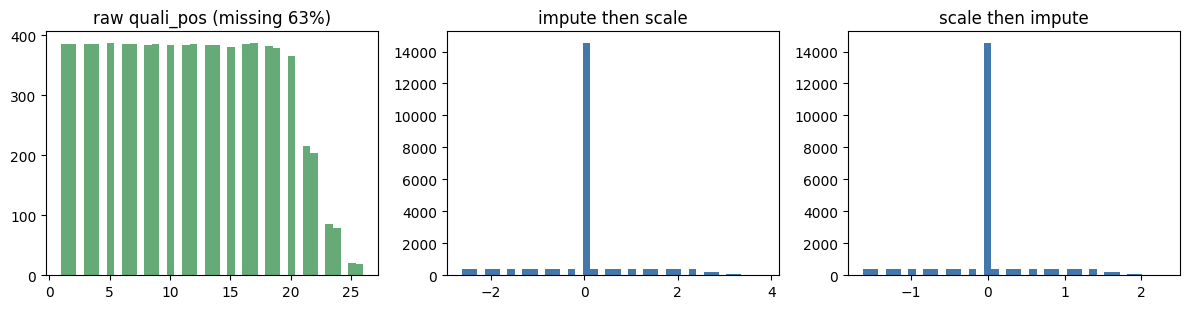

In [6]:
p2_rows = []
for order in ["impute_then_scale", "scale_then_impute"]:
    r = fit_eval(FEATURES, order=order)
    for split in ("val", "test"):
        p2_rows.append(dict(order=order, split=split, **r["metrics"][split]))
p2 = pd.DataFrame(p2_rows); p2.to_csv(os.path.join(OUT_RES, "p2_order.csv"), index=False)
display(p2.pivot(index="order", columns="split", values=["pr_auc", "roc_auc", "f1"]).round(4))

cols = [c for c in ["quali_pos", "quali_gap_pct", "grid_clean"] if c in CONTINUOUS][:2]
stat_rows = []
for order in ["impute_then_scale", "scale_then_impute"]:
    pre = make_preprocessor(CONTINUOUS, [], "linear", order).fit(train[FEATURES])
    X = pd.DataFrame(pre.transform(train[FEATURES])[:, :len(CONTINUOUS)], columns=CONTINUOUS)
    for c in cols:
        stat_rows.append(dict(order=order, feature=c, missing_share=train[c].isna().mean(), mean=X[c].mean(), std=X[c].std(), min=X[c].min(), max=X[c].max()))
display(pd.DataFrame(stat_rows).round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
c = cols[0]
axes[0].hist(train[c].dropna(), bins=40, color="#66AA77"); axes[0].set_title(f"raw {c} (missing {train[c].isna().mean():.0%})")
for ax, order in zip(axes[1:], ["impute_then_scale", "scale_then_impute"]):
    pre = make_preprocessor(CONTINUOUS, [], "linear", order).fit(train[FEATURES])
    ax.hist(pd.DataFrame(pre.transform(train[FEATURES])[:, :len(CONTINUOUS)], columns=CONTINUOUS)[c], bins=40, color="#4477AA")
    ax.set_title(order.replace("_", " "))
plt.tight_layout(); plt.savefig(os.path.join(OUT_FIG, "p2_order_hist.png"), dpi=150); plt.show()

## 6. Conclusions (computed from the tables above)

In [7]:
needed = ci[ci["clearly_needed"]]["group"].tolist()
print(f"Final model: {final['label']}. Full model validation PR-AUC {full_val['pr_auc']:.3f}.")
print(f"Largest drop when removed: {ci.iloc[0]['group']} ({ci.iloc[0]['delta_pr_auc']:+.4f}); "
      f"groups whose removal clearly hurts (interval below 0): {needed or 'none'}.")
best_alone = ci.sort_values("pr_auc_group_alone", ascending=False).iloc[0]
print(f"Strongest group on its own: {best_alone['group']} (PR-AUC {best_alone['pr_auc_group_alone']:.3f}).")
pv = p1[p1.split == "val"].set_index("pipeline")["pr_auc"]
print(f"P1: validation PR-AUC correct {pv.iloc[0]:.4f} vs leaky {pv.iloc[1]:.4f} "
      f"(largest median shift {shift['median_shift_in_std'].max():.3f} train SDs).")
qv = p2[p2.split == "val"].set_index("order")["pr_auc"]
print(f"P2: validation PR-AUC impute->scale {qv['impute_then_scale']:.4f} vs scale->impute {qv['scale_then_impute']:.4f}.")

Final model: Logistic regression. Full model validation PR-AUC 0.737.
Largest drop when removed: qualifying (-0.0168); groups whose removal clearly hurts (interval below 0): ['qualifying'].
Strongest group on its own: qualifying (PR-AUC 0.667).
P1: validation PR-AUC correct 0.7369 vs leaky 0.7372 (largest median shift 0.330 train SDs).
P2: validation PR-AUC impute->scale 0.7369 vs scale->impute 0.7335.


**Reading the results**
- **Ablation:** a group matters when removing it lowers PR-AUC with an interval below 0. Small changes with intervals crossing 0 mean the other groups cover for it (grid and qualifying overlap strongly). "Only this group" shows which groups carry signal by themselves. This is reliance of *this model* on the features, not proof that a feature *causes* podiums.
- **P1:** with 22k training rows the leaked statistics move only slightly, so the score barely changes; it is still invalid, because evaluation seasons influenced the transformation. With smaller training sets or drifting eras the gap would be larger.
- **P2:** scaling first makes the filled-in value the median of the scaled column; the column then no longer has standard deviation 1 (see the table), which is why impute-then-scale is used.

**Limitations:** one chronological split; validation has only 39 races; correlated groups make leave-one-out understate shared information.